# Structural credit risk under climate shocks

Merton and Black–Cox foundations, climate-extended firm-value models, and investor valuation losses.

Run the notebook from top to bottom. Local section numbers are retained within each part.

1. [13a: Structural Credit-Risk Baselines: Merton and Black-Cox](#part-13a)
2. [13b: Extended Merton Climate Model and Asset-Shock Analogues](#part-13b)
3. [13c: Reinders Credit-Transition Mark-to-Market Loss Model](#part-13c)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from quanttoolbox.credit.structural import pd_merton_model
from quanttoolbox.credit.structural import pd_black_cox_model
import pandas as pd
from scipy.stats import norm
from quanttoolbox.credit.structural import e0_extended_merton_model
from quanttoolbox.credit.structural import b0_extended_merton_model
from quanttoolbox.credit.structural import pd_extended_merton_model
from quanttoolbox.credit.structural import reinders_credit_model
from quanttoolbox.maths.numerical_diff import numerical_gradient
from quanttoolbox.maths.numerical_diff import numerical_hessian

<a id="part-13a"></a>

## Part 1 — 13a: Structural Credit-Risk Baselines: Merton and Black-Cox

The Merton (1974) model's equity-implied asset-value/volatility
calibration and default probability, and the Black-Cox (1976)
first-passage-time default probability — the two classic "structural"
credit-risk models that this chapter's later climate extensions build
on.

**Implementation note:** `pd_merton_model` and `pd_black_cox_model`
aren't available as ready-made implementations elsewhere in this
project, so they were built and verified here as
`quanttoolbox.credit.structural.pd_merton_model`/`pd_black_cox_model`.
Each returns a small bundle of related outputs — asset value, asset
volatility, distance-to-default, and PD for the Merton model;
first-passage PD alongside its intermediate quantities for Black-Cox.

**Reconstruction note:** the three-curve PD-vs-maturity plot in the
first section (three `(sigma_E, mu_A)` scenarios swept over
`tau=0..10`) had unclear axis/legend context to build from directly.
The scenario parameters were inferred from the legend labels and axis
range, and the resulting curves reproduce the expected textbook shape.


In [2]:
color_blue = "#1f77b4"
color_red = "#d62728"
color_green = "#2ca02c"
color_violet = "#ff33ff"
color_black = "#000000"
color_white = "#ffffff"

colors = [color_blue, color_red, color_green, color_violet]

plt.rcParams["figure.dpi"] = 100

### 1. Merton model: calibrated PD and PD-vs-maturity sensitivity

`E0=3`, `sigma_E=40%`, `D=10`, `mu_A=7%`, `r=5%`, `T=1`, `tau=1`: the
single-point calibrated asset value `A0`, asset volatility `sigma_A`,
distance-to-default `DD`, and PD (in bps). Then, as reconstructed
above, PD swept over `tau=0..10` for 3 `(sigma_E, mu_A)` scenarios.


In [3]:
E0, sigma_E, D, mu_A, r, T, tau = 3, 0.40, 10, 0.07, 0.05, 1, 1

r1 = pd_merton_model(E0, sigma_E, D, mu_A, r, T, tau)
print(f"{r1.a0:10.3f} {100 * r1.sigma_a:10.3f} {r1.dd_tau:10.3f} {1e4 * r1.pd_tau:10.3f}")
print("(A0, sigma_A %, DD, PD in bps)")

    12.512      9.609      3.012     12.962
(A0, sigma_A %, DD, PD in bps)


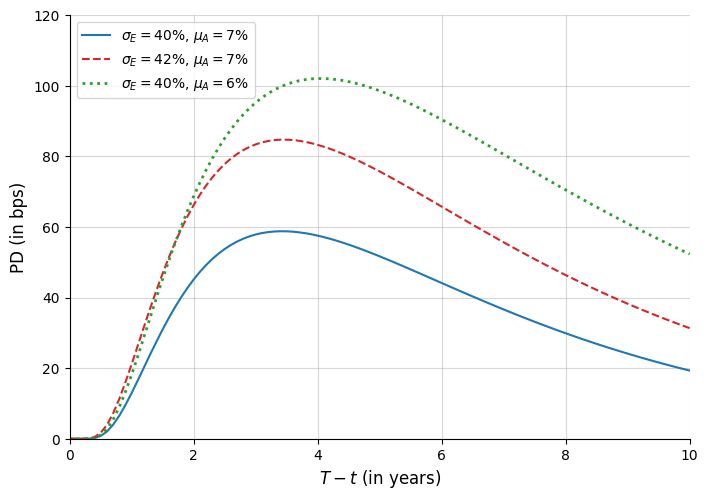

In [4]:
# Three-curve PD-vs-tau plot for the (sigma_E, mu_A) scenarios above
tau_grid = np.arange(0, 10.01, 0.1)
scenarios = [
    (0.40, 0.07, "-", color_blue, r"$\sigma_E = 40\%$, $\mu_A = 7\%$"),
    (0.42, 0.07, "--", color_red, r"$\sigma_E = 42\%$, $\mu_A = 7\%$"),
    (0.40, 0.06, ":", color_green, r"$\sigma_E = 40\%$, $\mu_A = 6\%$"),
]

fig, ax = plt.subplots(figsize=(8, 5.5))
with np.errstate(divide="ignore", invalid="ignore"):
    # tau=0 is a 0/0-or-x/0 boundary case: PD -> 0 as the horizon -> 0
    for sig_e, mu_a_i, style, c, label in scenarios:
        res = pd_merton_model(E0, sig_e, D, mu_a_i, r, T, tau_grid)
        pd_curve = np.nan_to_num(1e4 * res.pd_tau, nan=0.0)
        ax.plot(
            tau_grid, pd_curve, style, color=c, linewidth=1.5 if style != ":" else 2.0, label=label
        )

ax.set_xlabel("$T-t$ (in years)", fontsize=12)
ax.set_ylabel("PD (in bps)", fontsize=12)
ax.legend(fontsize=10, loc="upper left")
ax.grid(True, alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, 10)
ax.set_xticks(range(0, 11, 2))
ax.set_ylim(0, 120)
ax.set_yticks(range(0, 121, 20))
plt.show()

### 2. Merton model: PD vs. asset drift `mu_A`

The Merton model's PD plotted vs. `mu_A` (0-10%) for three scenarios:
`(T-t=1, D=10)`, `(T-t=2, D=10)`, `(T-t=1, D=15)` — with `E0=3`,
`sigma_E=40%`, `r=5%`, `T=1` fixed throughout.


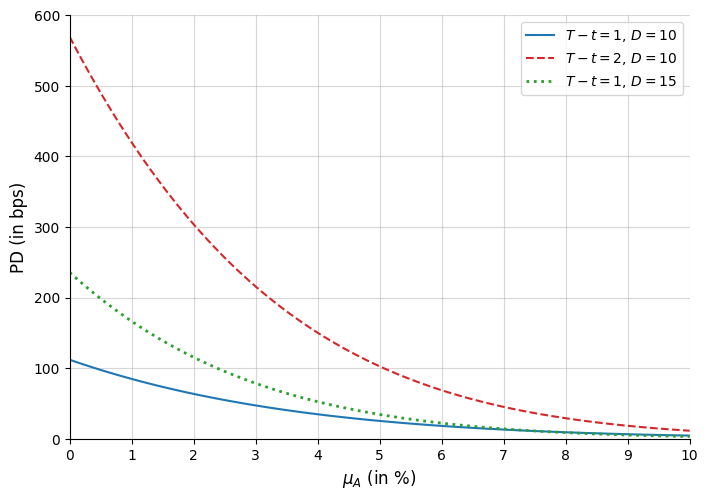

In [5]:
E0, sigma_E, r, T = 3, 0.40, 0.05, 1
mu_A_grid = np.arange(0, 0.1001, 0.001)

y1 = pd_merton_model(E0, sigma_E, 10, mu_A_grid, r, T, 1).pd_tau
y2 = pd_merton_model(E0, sigma_E, 10, mu_A_grid, r, T, 2).pd_tau
y3 = pd_merton_model(E0, sigma_E, 15, mu_A_grid, r, T, 1).pd_tau

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(100 * mu_A_grid, 1e4 * y1, "-", color=color_blue, linewidth=1.5, label="$T-t=1$, $D=10$")
ax.plot(100 * mu_A_grid, 1e4 * y2, "--", color=color_red, linewidth=1.5, label="$T-t=2$, $D=10$")
ax.plot(100 * mu_A_grid, 1e4 * y3, ":", color=color_green, linewidth=2.0, label="$T-t=1$, $D=15$")

ax.set_xlabel(r"$\mu_A$ (in %)", fontsize=12)
ax.set_ylabel("PD (in bps)", fontsize=12)
ax.legend(fontsize=10, loc="upper right")
ax.grid(True, alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, 10)
ax.set_xticks(range(0, 11, 1))
ax.set_ylim(0, 600)
ax.set_yticks(range(0, 601, 100))
plt.show()

### 3. Black-Cox model: 4-panel first-passage PD sensitivity

The Black-Cox model's first-passage PD swept individually over `t`,
`B` (barrier), `mu_A`, and `sigma_A`, each panel overlaying the base-case
point (`A0=30`, `B=15`, `mu_A=5%`, `sigma_A=20%`, `tau=5`) as a white
circle on the continuous curve.


PD=6.9388%  d1=1.8853  d2=-1.2145  varphi=0.3536


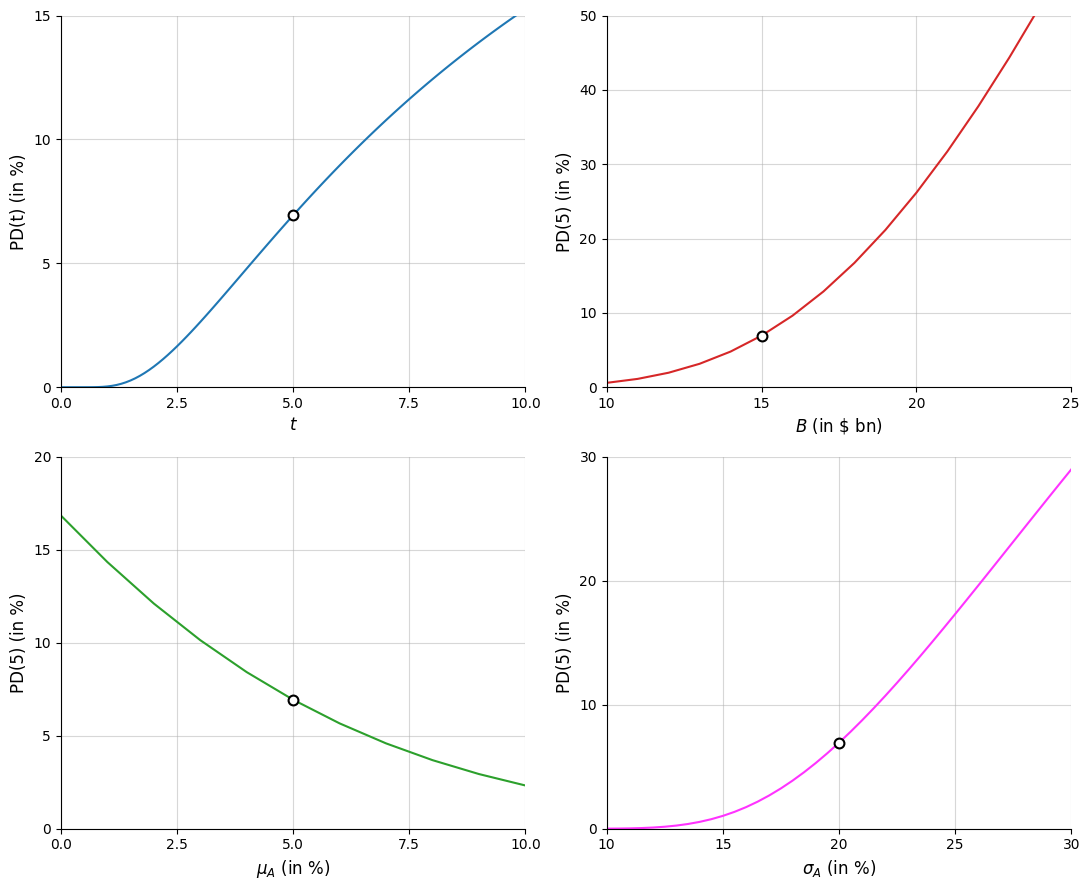

In [6]:
A0, B0, mu_A0, sigma_A0, tau0 = 30, 15, 0.05, 0.20, 5

with np.errstate(divide="ignore", invalid="ignore"):
    # base case
    base = pd_black_cox_model(A0, mu_A0, sigma_A0, B0, tau0)
    x0 = [tau0, B0, 100 * mu_A0, 100 * sigma_A0]
    y0 = base.pd_tau
    print(f"PD={100 * y0:.4f}%  d1={base.d1:.4f}  d2={base.d2:.4f}  varphi={base.varphi:.4f}")

    tau_v = np.arange(0, 10.01, 0.1)
    x1, y1 = tau_v, pd_black_cox_model(A0, mu_A0, sigma_A0, B0, tau_v).pd_tau

    B_v = np.arange(10, 25.01, 1)
    x2, y2 = B_v, pd_black_cox_model(A0, mu_A0, sigma_A0, B_v, tau0).pd_tau

    mu_A_v = np.arange(0, 0.1001, 0.01)
    x3, y3 = 100 * mu_A_v, pd_black_cox_model(A0, mu_A_v, sigma_A0, B0, tau0).pd_tau

    sigma_A_v = np.arange(0.10, 0.3001, 0.005)
    x4, y4 = 100 * sigma_A_v, pd_black_cox_model(A0, mu_A0, sigma_A_v, B0, tau0).pd_tau

panels = [
    (x1, y1, "$t$", (0, 10), 2.5, (0, 15), 5, "PD(t) (in %)"),
    (x2, y2, r"$B$ (in \$ bn)", (10, 25), 5, (0, 50), 10, "PD(5) (in %)"),
    (x3, y3, r"$\mu_A$ (in %)", (0, 10), 2.5, (0, 20), 5, "PD(5) (in %)"),
    (x4, y4, r"$\sigma_A$ (in %)", (10, 30), 5, (0, 30), 10, "PD(5) (in %)"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for i, (ax, (x, y, xlabel, xlim, dx, ylim, dy, ylabel)) in enumerate(zip(axes.flat, panels)):
    y_clean = np.nan_to_num(100 * np.asarray(y), nan=0.0)
    ax.plot(x, y_clean, "-", color=colors[i], linewidth=1.5)
    ax.scatter(
        [x0[i]],
        [100 * y0],
        s=50,
        facecolors=color_white,
        edgecolors=color_black,
        linewidths=1.5,
        zorder=5,
    )
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.grid(True, alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(*xlim)
    ax.set_xticks(np.arange(xlim[0], xlim[1] + 1e-9, dx))
    ax.set_ylim(*ylim)
    ax.set_yticks(np.arange(ylim[0], ylim[1] + 1e-9, dy))

plt.tight_layout()
plt.show()

<a id="part-13b"></a>

## Part 2 — 13b: Extended Merton Climate Model and Asset-Shock Analogues

Blasberg (2024)'s climate-extended Merton model, where the firm's
discount/growth factor `delta(t)` is itself a Brownian motion
correlated with the asset value (a way of encoding a climate-driven
drag on firm value that is itself uncertain and correlated with the
underlying business), plus two related plain-Merton exercises
quantifying an instantaneous climate-driven asset-value haircut.

**Implementation note:** `e0_extended_merton_model`,
`b0_extended_merton_model`, and `pd_extended_merton_model` aren't
available as ready-made implementations elsewhere in this project, so
they were built here as
`quanttoolbox.credit.structural.{e0,b0,pd}_extended_merton_model`. The
first section below is itself a self-verification suite for these
three functions, and every one of its checks passes to essentially
machine precision.


### 1. Self-verification: balance-sheet identity, standard-Merton recovery, monotonicity

Three checks on `e0_extended_merton_model`/`b0_extended_merton_model`/
`pd_extended_merton_model`, reproduced here as printed PASS/FAIL
results:
1. Balance-sheet identity `E0 + B0 = A0 * exp(-delta0'*T)`.
2. Recovery of the classical Black-Scholes-Merton formulas when
   `delta0 = mu_delta = sigma_delta = 0`.
3. Monotonicity of PD in the climate drift `mu_delta`.


In [7]:
def check(cond):
    return "PASS" if cond else "FAIL"


A0, D, r, mu_A = 100, 80, 0.03, 0.07
delta0, mu_delta, sigma_A, sigma_delta, rho, T = 0.01, 0.005, 0.20, 0.04, -0.30, 5

E0 = e0_extended_merton_model(A0, D, r, mu_A, delta0, mu_delta, sigma_A, sigma_delta, rho, T)
B0 = b0_extended_merton_model(A0, D, r, mu_A, delta0, mu_delta, sigma_A, sigma_delta, rho, T)
PD = pd_extended_merton_model(A0, D, r, mu_A, delta0, mu_delta, sigma_A, sigma_delta, rho, T)

print("=== Extended Merton model - sanity checks ===\n")
print("Base parameters:")
print(f"  E0  = {E0:.6f}")
print(f"  B0  = {B0:.6f}")
print(f"  PD  = {PD:.6f}")

=== Extended Merton model - sanity checks ===

Base parameters:
  E0  = 34.404728
  B0  = 60.797517
  PD  = 0.264022


In [8]:
# Test 1: balance-sheet identity
sigma_A_prime = np.sqrt(
    sigma_A**2 - rho * sigma_A * sigma_delta * T + (1 / 3) * sigma_delta**2 * T**2
)
delta0_prime = (
    delta0
    + 0.5 * mu_delta * T
    + 0.5 * rho * sigma_A * sigma_delta * T
    - (1 / 6) * sigma_delta**2 * T**2
)
rhs = A0 * np.exp(-delta0_prime * T)

err1 = abs(E0 + B0 - rhs)
print("Test 1 - Balance-sheet identity  E0 + B0 = A0*exp(-delta0'*T):")
print(f"  E0 + B0            = {E0 + B0:.6f}")
print(f"  A0*exp(-delta0'*T) = {rhs:.6f}")
print(f"  Error              = {err1:.2e}  {check(err1 < 1e-10)}")

Test 1 - Balance-sheet identity  E0 + B0 = A0*exp(-delta0'*T):
  E0 + B0            = 95.202245
  A0*exp(-delta0'*T) = 95.202245
  Error              = 0.00e+00  PASS


In [9]:
# Test 2: standard Merton recovery (delta0 = mu_delta = sigma_delta = 0)
E0_ext = e0_extended_merton_model(A0, D, r, mu_A, 0, 0, sigma_A, 0, 0, T)
B0_ext = b0_extended_merton_model(A0, D, r, mu_A, 0, 0, sigma_A, 0, 0, T)
PD_ext = pd_extended_merton_model(A0, D, r, mu_A, 0, 0, sigma_A, 0, 0, T)

d1_std = (np.log(A0 / D) + r * T) / (sigma_A * np.sqrt(T)) + 0.5 * sigma_A * np.sqrt(T)
d2_std = d1_std - sigma_A * np.sqrt(T)
E0_std = A0 * norm.cdf(d1_std) - D * np.exp(-r * T) * norm.cdf(d2_std)
B0_std = A0 * norm.cdf(-d1_std) + D * np.exp(-r * T) * norm.cdf(d2_std)
DD_std = (np.log(A0 / D) + (mu_A - 0.5 * sigma_A**2) * T) / (sigma_A * np.sqrt(T))
PD_std = norm.cdf(-DD_std)

err2_E0, err2_B0, err2_PD = abs(E0_ext - E0_std), abs(B0_ext - B0_std), abs(PD_ext - PD_std)
print("Test 2 - Standard Merton recovery (delta0=mu_delta=sigma_delta=0):")
print(f"  E0 error = {err2_E0:.2e}  {check(err2_E0 < 1e-10)}")
print(f"  B0 error = {err2_B0:.2e}  {check(err2_B0 < 1e-10)}")
print(f"  PD error = {err2_PD:.2e}  {check(err2_PD < 1e-10)}")

Test 2 - Standard Merton recovery (delta0=mu_delta=sigma_delta=0):
  E0 error = 0.00e+00  PASS
  B0 error = 0.00e+00  PASS
  PD error = 0.00e+00  PASS


In [10]:
# Test 3: monotonicity - PD increases with mu_delta
mu_delta_vec = [0, 0.002, 0.005, 0.010, 0.020]
rows = []
pd_prev, mono_ok = -np.inf, True
for md_i in mu_delta_vec:
    e0k = e0_extended_merton_model(A0, D, r, mu_A, delta0, md_i, sigma_A, sigma_delta, rho, T)
    b0k = b0_extended_merton_model(A0, D, r, mu_A, delta0, md_i, sigma_A, sigma_delta, rho, T)
    pdk = pd_extended_merton_model(A0, D, r, mu_A, delta0, md_i, sigma_A, sigma_delta, rho, T)
    rows.append([md_i, e0k, b0k, pdk])
    if pdk < pd_prev - 1e-12:
        mono_ok = False
    pd_prev = pdk

print("Test 3 - Monotonicity: PD increases with mu_delta:")
display(pd.DataFrame(rows, columns=["mu_delta", "E0", "B0", "PD"]).round(4))
print(f"  Monotonicity check: {check(mono_ok)}")
print("\n=== All tests complete ===")

Test 3 - Monotonicity: PD increases with mu_delta:


,mu_delta,E0,B0,PD
0,0.000,39.4267,61.9156,0.2295
1,0.002,37.3588,61.4813,0.2430
2,0.005,34.4047,60.7975,0.2640
3,0.010,29.8619,59.5724,0.3010
4,0.020,22.1141,56.8113,0.3810


  Monotonicity check: PASS

=== All tests complete ===


### 2. PD vs. `delta0` sensitivity

The extended Merton model's PD swept over `delta0` (0-10%) for 4
`(mu_delta, sigma_delta, rho)` scenarios, including the degenerate
`(0,0,0)` case that collapses to standard Merton.


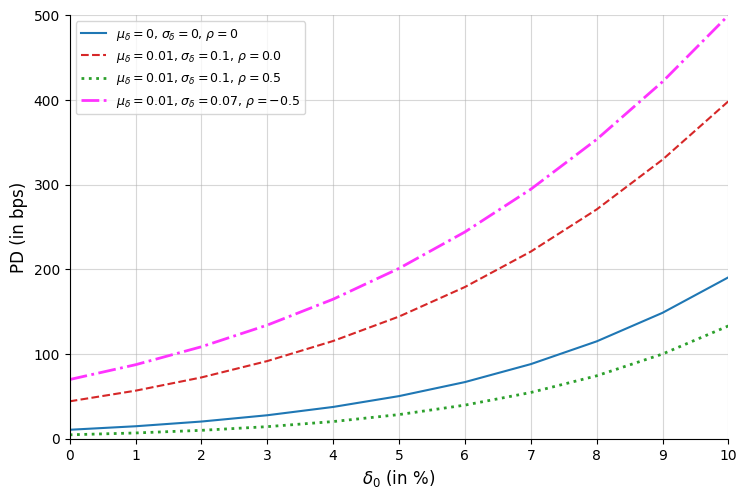

In [11]:
A0, mu_A, sigma_A, D, r, T = 13, 0.05, 0.10, 10, 0.05, 1
delta0_grid = np.arange(0, 0.1001, 0.01)

scenarios5 = [
    (0, 0, 0, "-", color_blue, 1.5),
    (0.01, 0.10, 0.0, "--", color_red, 1.5),
    (0.01, 0.10, 0.5, ":", color_green, 2.0),
    (0.01, 0.07, -0.5, "-.", color_violet, 2.0),
]

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for mu_d, sig_d, rho_i, style, c, lw in scenarios5:
    pd_curve = pd_extended_merton_model(A0, D, r, mu_A, delta0_grid, mu_d, sigma_A, sig_d, rho_i, T)
    label = rf"$\mu_\delta={mu_d}$, $\sigma_\delta={sig_d}$, $\rho={rho_i}$"
    ax.plot(100 * delta0_grid, 1e4 * pd_curve, style, color=c, linewidth=lw, label=label)

ax.set_xlabel(r"$\delta_0$ (in %)", fontsize=12)
ax.set_ylabel("PD (in bps)", fontsize=12)
ax.legend(fontsize=9, loc="upper left")
ax.grid(True, alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, 10)
ax.set_xticks(range(0, 11, 1))
ax.set_ylim(0, 500)
ax.set_yticks(range(0, 501, 100))
plt.show()

### 3. Plain-Merton asset-haircut PD sensitivity

An instantaneous asset-value haircut `A_t = (1-xi(t))*A0` applied to a
standard (non-extended) Merton distance-to-default, for a fine 1-10%
haircut table (with the average marginal-PD sensitivity `delta`) and a
coarse 0-25% plot.


Baseline PD (bps): 166.41


,xi_t,PD (bps),PD - PD0 (bps)
0,0.01,180.02,13.61
1,0.02,194.72,28.31
2,0.03,210.59,44.18
3,0.04,227.73,61.32
4,0.05,246.23,79.82
5,0.06,266.18,99.77
6,0.07,287.71,121.30
7,0.08,310.91,144.50
8,0.09,335.93,169.52
9,0.10,362.88,196.47


Average marginal PD sensitivity: 16.4288 bps per 1% haircut


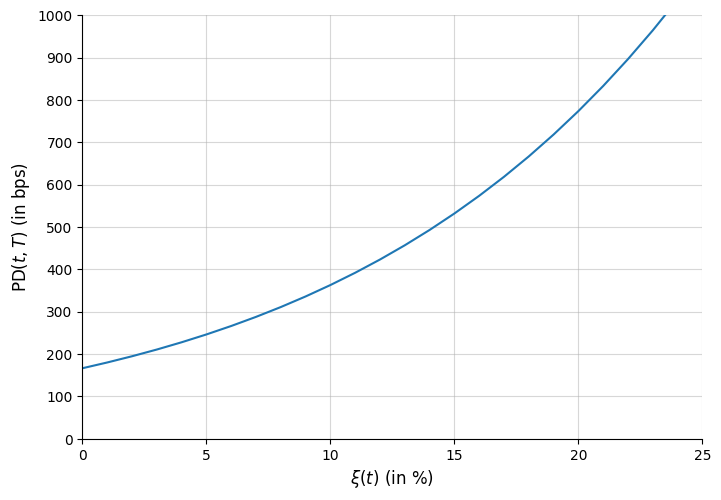

In [12]:
A0, mu_A, sigma_A, D, T = 25, 0.05, 0.10, 20, 10

DD0 = (np.log(A0 / D) + (mu_A - 0.5 * sigma_A**2) * T) / (sigma_A * np.sqrt(T))
PD0 = norm.cdf(-DD0)
print(f"Baseline PD (bps): {1e4 * PD0:.2f}")

xi_t = np.arange(0.01, 0.1001, 0.01)
A_t = (1 - xi_t) * A0
DD1 = (np.log(A_t / D) + (mu_A - 0.5 * sigma_A**2) * T) / (sigma_A * np.sqrt(T))
PD1 = norm.cdf(-DD1)
table6 = pd.DataFrame({"xi_t": xi_t, "PD (bps)": 1e4 * PD1, "PD - PD0 (bps)": 1e4 * (PD1 - PD0)})
display(table6.round(2))

delta_sens = np.mean(1e4 * (PD1 - PD0) / (1e2 * xi_t))
print(f"Average marginal PD sensitivity: {delta_sens:.4f} bps per 1% haircut")

xi_t_plot = np.arange(0, 0.2501, 0.01)
A_t_plot = (1 - xi_t_plot) * A0
DD_plot = (np.log(A_t_plot / D) + (mu_A - 0.5 * sigma_A**2) * T) / (sigma_A * np.sqrt(T))
PD_plot = norm.cdf(-DD_plot)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(100 * xi_t_plot, 1e4 * PD_plot, "-", color=color_blue, linewidth=1.5)
ax.set_xlabel(r"$\xi(t)$ (in %)", fontsize=12)
ax.set_ylabel(r"$\mathrm{PD}(t,T)$ (in bps)", fontsize=12)
ax.grid(True, alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, 25)
ax.set_xticks(range(0, 26, 5))
ax.set_ylim(0, 1000)
ax.set_yticks(range(0, 1001, 100))
plt.show()

### 4. Implied drift adjustment for a PD-preserving haircut

The drift adjustment `Delta mu_A*(t)` that reproduces a given asset-value
haircut `xi(t)` when applied multiplicatively over the horizon
(`exp(-Delta_mu*T) = 1-xi(t)`, i.e. `Delta_mu_A = -ln(1-xi)/T`), compared
against its first-order (small-`xi`) approximation `xi/T`, for two
maturities. The corresponding distance-to-default/PD-under-haircut
quantities aren't needed for this comparison, so only the two closed
forms and the `xi/T` approximation are computed here.


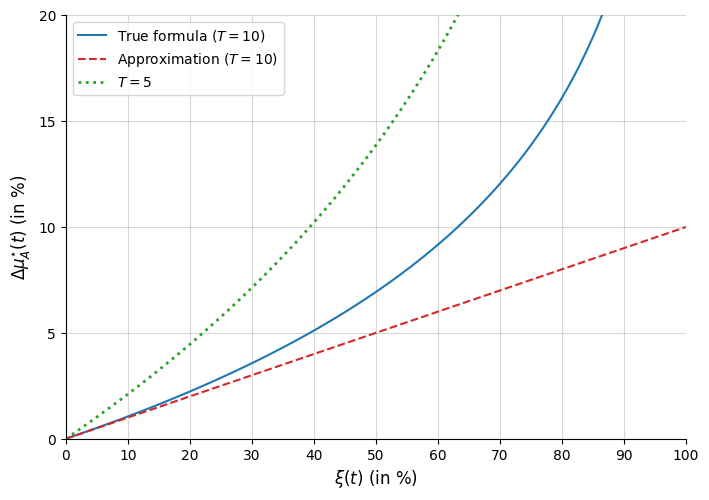

In [13]:
T5, T10 = 5, 10
xi_t7 = np.arange(0, 1.001, 0.01)

with np.errstate(divide="ignore"):
    # xi_t=1.0 (100% haircut) gives log(0) = -inf
    Delta_mu_A_5 = -(1 / T5) * np.log(1 - xi_t7)
    Delta_mu_A_10 = -(1 / T10) * np.log(1 - xi_t7)
approx_10 = xi_t7 / T10

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(
    100 * xi_t7,
    100 * Delta_mu_A_10,
    "-",
    color=color_blue,
    linewidth=1.5,
    label="True formula ($T=10$)",
)
ax.plot(
    100 * xi_t7,
    100 * approx_10,
    "--",
    color=color_red,
    linewidth=1.5,
    label="Approximation ($T=10$)",
)
ax.plot(100 * xi_t7, 100 * Delta_mu_A_5, ":", color=color_green, linewidth=2.0, label="$T=5$")

ax.set_xlabel(r"$\xi(t)$ (in %)", fontsize=12)
ax.set_ylabel(r"$\Delta \mu_A^{\star}(t)$ (in %)", fontsize=12)
ax.legend(fontsize=10, loc="upper left")
ax.grid(True, alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 10))
ax.set_ylim(0, 20)
ax.set_yticks(range(0, 21, 5))
plt.show()

<a id="part-13c"></a>

## Part 3 — 13c: Reinders Credit-Transition Mark-to-Market Loss Model

The Reinders et al. equity+debt mark-to-market loss under an
instantaneous asset-value haircut `A(t)=A0*(1-xi)`, weighted by an
investor's equity/debt holding shares `omega_E`/`omega_D` —
self-verified against a numerical-differentiation cross-check, then
plotted (loss, first derivative, second derivative) across 4
`(omega_E, omega_D)` scenarios.

**Implementation note:** `reinders_credit_model` isn't available as a
ready-made implementation elsewhere in this project, so it was built
here as `quanttoolbox.credit.structural.reinders_credit_model`. Its
`mu_A` parameter is dropped from the signature entirely, since it never
enters the underlying loss formula. `numerical_gradient`/
`numerical_hessian`, generic finite-difference utilities, are reused
from `quanttoolbox.maths.numerical_diff` elsewhere in this project.

**Notebook structure note:** the three loss-derivative plots below
(`Loss`, `D_Loss`, `D2_Loss`) share the same parameters and the same
`reinders_credit_model` call, differing only in which output column
they plot — so the computation is done once, followed by three plot
cells, rather than repeating the setup three times.


### 1. Self-verification: numerical vs. analytic loss gradient/Hessian

At each `xi` on a `0.00:0.05:0.99` grid, `reinders_credit_model`'s
analytic `D_Loss`/`D2_Loss` are compared against a numerical
gradient/Hessian applied to the underlying plain-Merton equity/debt
value formulas (`merton_mv_e`, `merton_mv_d`, defined locally below),
and against the *further* closed-form first derivative of those same
formulas (`g2_E`, `g2_D`, via `-A0*normcdf(d1)`/`-A0*normcdf(-d1)`) —
three independent routes to the same underlying quantity.


In [14]:
A0, D, r, mu_A, sigma_A, T = 25, 20, 0.03, 0.05, 0.10, 10
omega_E, omega_D = 0.10, 0.20


def merton_mv_e(xi):
    xi = float(np.asarray(xi).item())
    A_t = A0 * (1 - xi)
    d1 = (np.log(A_t / D) + r * T) / (sigma_A * np.sqrt(T)) + 0.5 * sigma_A * np.sqrt(T)
    d2 = d1 - sigma_A * np.sqrt(T)
    return A_t * norm.cdf(d1) - D * np.exp(-r * T) * norm.cdf(d2)


def merton_mv_d(xi):
    xi = float(np.asarray(xi).item())
    A_t = A0 * (1 - xi)
    d1 = (np.log(A_t / D) + r * T) / (sigma_A * np.sqrt(T)) + 0.5 * sigma_A * np.sqrt(T)
    d2 = d1 - sigma_A * np.sqrt(T)
    return A_t * norm.cdf(-d1) + D * np.exp(-r * T) * norm.cdf(d2)


rows = []
for xi in np.arange(0.00, 0.991, 0.05):
    g1_E = numerical_gradient(merton_mv_e, np.array([xi]))[0]
    g1_D = numerical_gradient(merton_mv_d, np.array([xi]))[0]
    A_t = A0 * (1 - xi)
    d1 = (np.log(A_t / D) + r * T) / (sigma_A * np.sqrt(T)) + 0.5 * sigma_A * np.sqrt(T)
    g2_E = -A0 * norm.cdf(d1)
    g2_D = -A0 * norm.cdf(-d1)
    grd_Loss = -omega_E * g1_E - omega_D * g1_D
    h1_E = numerical_hessian(merton_mv_e, np.array([xi]))[0, 0]
    h1_D = numerical_hessian(merton_mv_d, np.array([xi]))[0, 0]
    hss_Loss = -omega_E * h1_E - omega_D * h1_D
    res = reinders_credit_model(xi, A0, D, r, sigma_A, T, omega_E, omega_D)
    rows.append([xi, g1_E, g2_E, g1_D, g2_D, grd_Loss, res.d_loss, hss_Loss, res.d2_loss])

cols8a = [
    "xi",
    "g1_E (num)",
    "g2_E (analytic)",
    "g1_D (num)",
    "g2_D (analytic)",
    "grd_Loss (num)",
    "D_Loss (model)",
    "hss_Loss (num)",
    "D2_Loss (model)",
]
display(pd.DataFrame(rows, columns=cols8a).round(4))

,xi,g1_E (num),g2_E (analytic),g1_D (num),g2_D (analytic),grd_Loss (num),D_Loss (model),hss_Loss (num),D2_Loss (model)
0,0.00,-24.1260,-24.1260,-0.8740,-0.8740,2.5874,2.5874,0.6104,0.6103
1,0.05,-23.7638,-23.7638,-1.2362,-1.2362,2.6236,2.6236,0.8508,0.8507
2,0.10,-23.2616,-23.2616,-1.7384,-1.7384,2.6738,2.6738,1.1734,1.1734
3,0.15,-22.5736,-22.5736,-2.4264,-2.4264,2.7426,2.7426,1.5970,1.5970
4,0.20,-21.6452,-21.6452,-3.3548,-3.3548,2.8355,2.8355,2.1369,2.1368
5,0.25,-20.4165,-20.4165,-4.5835,-4.5835,2.9584,2.9584,2.7982,2.7979
6,0.30,-18.8295,-18.8295,-6.1705,-6.1705,3.1170,3.1170,3.5648,3.5645
7,0.35,-16.8428,-16.8428,-8.1572,-8.1572,3.3157,3.3157,4.3849,4.3846
8,0.40,-14.4528,-14.4528,-10.5472,-10.5472,3.5547,3.5547,5.1558,5.1554
9,0.45,-11.7220,-11.7220,-13.2780,-13.2780,3.8278,3.8278,5.7171,5.7169


### 2. Loss, first derivative, and second derivative vs. haircut

The Reinders model's portfolio loss `L(xi)` (and its 1st/2nd
derivatives) plotted vs. haircut `xi` (0-99.9%), for 4 `(omega_E,
omega_D)` equity/debt-weight combinations.


In [15]:
xi_t = np.concatenate([[0.0], np.arange(0.01, 0.9901, 0.01), [0.999]])
omega_E_v = np.array([0.10, 0.20, 0.50, 0.90])
omega_D_v = np.array([0.30, 0.70, 0.30, 0.10])

res8 = reinders_credit_model(
    xi_t[:, None], A0, D, r, sigma_A, T, omega_E_v[None, :], omega_D_v[None, :]
)

styles = ["-", "--", ":", "-."]
colors8 = [color_blue, color_red, color_green, color_violet]
widths8 = [1.5, 1.5, 2.0, 1.5]
labels8 = [rf"$\omega_E={omega_E_v[i]:.2f}$, $\omega_D={omega_D_v[i]:.2f}$" for i in range(4)]

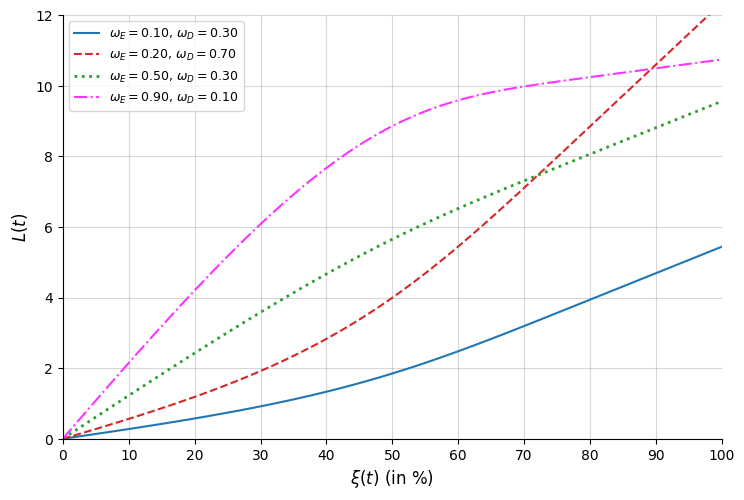

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i in range(4):
    ax.plot(
        100 * xi_t,
        res8.loss[:, i],
        styles[i],
        color=colors8[i],
        linewidth=widths8[i],
        label=labels8[i],
    )

ax.set_xlabel(r"$\xi(t)$ (in %)", fontsize=12)
ax.set_ylabel(r"$L(t)$", fontsize=12)
ax.legend(fontsize=9, loc="upper left")
ax.grid(True, alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 10))
ax.set_ylim(0, 12)
ax.set_yticks(range(0, 13, 2))
plt.show()

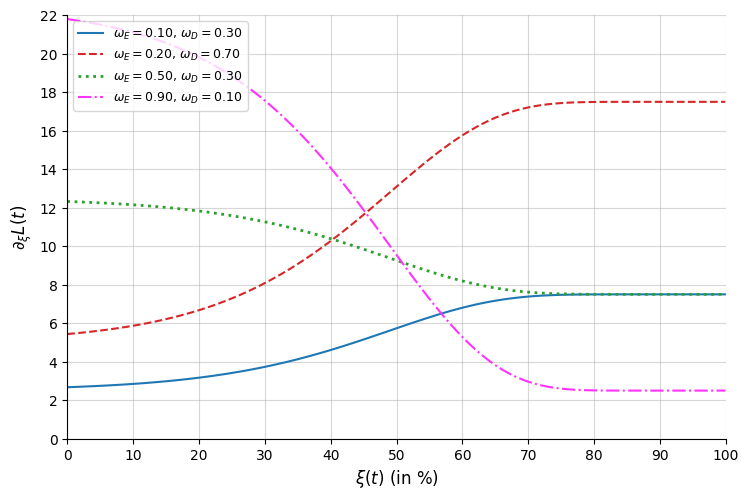

In [17]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i in range(4):
    ax.plot(
        100 * xi_t,
        res8.d_loss[:, i],
        styles[i],
        color=colors8[i],
        linewidth=widths8[i],
        label=labels8[i],
    )

ax.set_xlabel(r"$\xi(t)$ (in %)", fontsize=12)
ax.set_ylabel(r"$\partial_{\xi}L(t)$", fontsize=12)
ax.legend(fontsize=9, loc="upper left")
ax.grid(True, alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 10))
ax.set_ylim(0, 22)
ax.set_yticks(range(0, 23, 2))
plt.show()

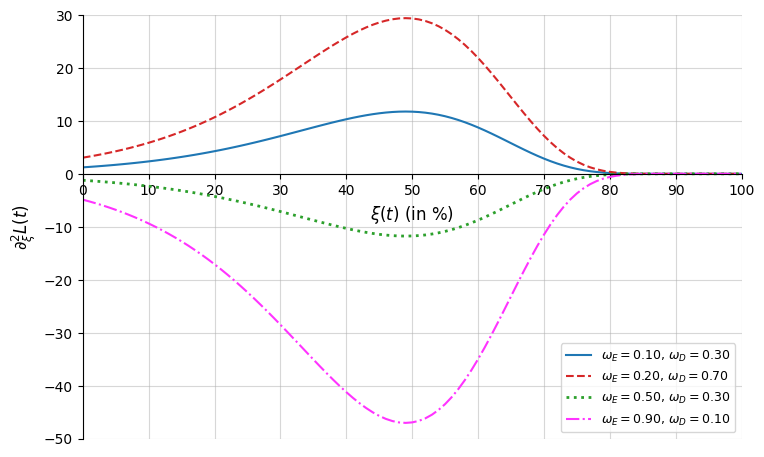

In [18]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i in range(4):
    ax.plot(
        100 * xi_t,
        res8.d2_loss[:, i],
        styles[i],
        color=colors8[i],
        linewidth=widths8[i],
        label=labels8[i],
    )

ax.set_xlabel(r"$\xi(t)$ (in %)", fontsize=12)
ax.set_ylabel(r"$\partial^{2}_{\xi}L(t)$", fontsize=12)
ax.legend(fontsize=9, loc="lower right")
ax.grid(True, alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_position("zero")
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 10))
ax.set_ylim(-50, 30)
ax.set_yticks(range(-50, 31, 10))
plt.show()